In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import yfinance as yf
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

In [2]:
# hyperparameters
train_test_prop = 0.8
batch_size = 16
block_size = 20 # the temporal block size of the model
epochs = 100
learning_rate = 0.0001
device = 'cuda' if torch.cuda.is_available() else 'cpu'
show_stats = True

# model parameters
n_hidden = 32
n_layer = 2
dropout = 0.2

torch.manual_seed(1337)

In [22]:
data = yf.download("AMZN", start="2006-01-01", end="2018-01-01")
data.columns = data.columns.droplevel(1)
data.reset_index(inplace=True)
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2006-01-03,2.3790,2.3790,2.3925,2.3125,2.3735,151644000
1,2006-01-04,2.3625,2.3625,2.3865,2.3345,2.3745,148818000
2,2006-01-05,2.3825,2.3825,2.4100,2.3555,2.3580,108344000
3,2006-01-06,2.3935,2.3935,2.4290,2.3660,2.3985,123058000
4,2006-01-09,2.3540,2.3540,2.3550,2.3200,2.3275,178862000


In [4]:
# data["1D Return"] = data["Close"].pct_change(1)
# data["5D Return"] = data["Close"].pct_change(5)
# data["20D Return"] = data["Close"].pct_change(20)
# data["80D Return"] = data["Close"].pct_change(80)
# data["120D Return"] = data["Close"].pct_change(120)
# data["160D Return"] = data["Close"].pct_change(160)
# data["200D Return"] = data["Close"].pct_change(200)
# data["20D EMA"] = data["Close"].ewm(span=20, adjust=False).mean()
# data["80D EMA"] = data["Close"].ewm(span=80, adjust=False).mean()
# data["120D EMA"] = data["Close"].ewm(span=120, adjust=False).mean()
# data["160D EMA"] = data["Close"].ewm(span=160, adjust=False).mean()
# data["200D EMA"] = data["Close"].ewm(span=200, adjust=False).mean()
data.dropna(inplace=True)

In [5]:
# data.drop(columns=["Adj Close", "Open", "High", "Low", "Volume"], inplace=True)
data

Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2006-01-03,2.379000,2.379000,2.392500,2.312500,2.373500,151644000
1,2006-01-04,2.362500,2.362500,2.386500,2.334500,2.374500,148818000
2,2006-01-05,2.382500,2.382500,2.410000,2.355500,2.358000,108344000
3,2006-01-06,2.393500,2.393500,2.429000,2.366000,2.398500,123058000
4,2006-01-09,2.354000,2.354000,2.355000,2.320000,2.327500,178862000
...,...,...,...,...,...,...,...
3015,2017-12-22,58.417999,58.417999,58.730999,58.391499,58.604000,31702000
3016,2017-12-26,58.838001,58.838001,58.916000,58.027500,58.417999,40104000
3017,2017-12-27,59.112999,59.112999,59.364498,58.780499,58.995499,37344000
3018,2017-12-28,59.305000,59.305000,59.505001,59.219002,59.450001,36834000


In [6]:
price = data[['Close']]
price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3020 entries, 0 to 3019
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3020 non-null   float64
dtypes: float64(1)
memory usage: 23.7 KB


In [7]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(-1, 1))
price['Close'] = scaler.fit_transform(price['Close'].values.reshape(-1,1))

C:\Users\luis\AppData\Local\Temp\ipykernel_20284\68737012.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  price['Close'] = scaler.fit_transform(price['Close'].values.reshape(-1,1))


In [8]:
# def split_data(stock, lookback):
#     data_raw = stock.to_numpy() # convert to numpy array
#     data = []
    
#     # create all possible sequences of length seq_len
#     for index in range(len(data_raw) - lookback): 
#         data.append(data_raw[index: index + lookback])
    
#     data = np.array(data);
#     test_set_size = int(np.round(0.2*data.shape[0]));
#     train_set_size = data.shape[0] - (test_set_size);
    
#     x_train = data[:train_set_size,:-1,:]
#     y_train = data[:train_set_size,-1,:]
    
#     x_test = data[train_set_size:,:-1]
#     y_test = data[train_set_size:,-1,:]
    
#     return [x_train, y_train, x_test, y_test]

In [9]:
# lookback = 20 # choose sequence length
# x_train, y_train, x_test, y_test = split_data(price, lookback)
# print('x_train.shape = ',x_train.shape)
# print('y_train.shape = ',y_train.shape)
# print('x_test.shape = ',x_test.shape)
# print('y_test.shape = ',y_test.shape)

In [10]:
# import torch
# import torch.nn as nn

# x_train = torch.from_numpy(x_train).type(torch.Tensor)
# x_test = torch.from_numpy(x_test).type(torch.Tensor)
# y_train_lstm = torch.from_numpy(y_train).type(torch.Tensor)
# y_test_lstm = torch.from_numpy(y_test).type(torch.Tensor)
# y_train_gru = torch.from_numpy(y_train).type(torch.Tensor)
# y_test_gru = torch.from_numpy(y_test).type(torch.Tensor)

In [11]:
x_train = price["Close"].values[:int(0.8*len(price))].reshape(-1, 1)
x_test = price["Close"].values[int(0.8*len(price)):-1].reshape(-1, 1)
y_train = price["Close"].values[1:int(0.8*len(price))].reshape(-1, 1)
y_test = price["Close"].values[int(0.8*len(price))+1:].reshape(-1, 1)


In [12]:
# x_train = x_train.to(device)
# x_test = x_test.to(device)
# y_train = y_train.to(device)
# y_test = y_test.to(device)

In [13]:
input_dim = 1
hidden_dim = 32
num_layers = 2
output_dim = 1
num_epochs = 100

In [14]:
class TimeSeriesDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.x = x
        self.y = y
        self.block_size = block_size

    def __len__(self):
        return len(self.y) - self.block_size + 1

    def __getitem__(self, idx):
        if idx + self.block_size > len(self.x):
            raise IndexError("Index out of bounds")
        return (
            torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
            torch.tensor(self.y[idx+self.block_size-1], dtype=torch.float32).unsqueeze(-1)
        )

In [15]:
train_dataset = TimeSeriesDataset(x_train, y_train, 20)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

test_dataset = TimeSeriesDataset(x_test, y_test, 20)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [16]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout):
        super(LSTMModel, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x: (batch_size, block_size, feature_size)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_().to(device)

        # Initialize cell state
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_().to(device)

        # We need to detach as we are doing truncated backpropagation through time (BPTT)
        # If we don't, we'll backprop all the way to the start even after going through another batch
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        
        # out: (batch_size, block_size, hidden_size), contains all hidden states in block_size. We only want the last one.
        out = self.fc(out[:, -1, :]) 

        # out: (batch_size, 1)
        return out
    

In [17]:
model = LSTMModel(input_size=input_dim, hidden_size=hidden_dim, num_layers=num_layers, dropout=0)
device = "cuda"
model = model.to(device)
criterion = torch.nn.MSELoss(reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [18]:
def run_epoch(model, criterion, loader, optimizer, is_train):
    if is_train:
        model.train()
    else:
        model.eval()
    
    epoch_loss = 0
    total_samples = 0

    for x, y in loader:
        if is_train:
            optimizer.zero_grad()
        
        x = x.to(device)
        y = y.to(device)
        
        batchsize = x.shape[0]
                            
        out = model(x)
        loss = criterion(out, y)

        if is_train:
            loss.backward()
            optimizer.step()

        epoch_loss += loss.item() * batchsize
        total_samples += batchsize
        #potential idea: only get validation loss every x epochs?
    
    return epoch_loss / total_samples


In [19]:
epochs = 100
train_losses = np.zeros(epochs)
test_losses = np.zeros(epochs)

for epoch in tqdm(range(epochs)):
    train_loss = run_epoch(model, criterion, train_loader, optimizer, is_train=True)
    test_loss = run_epoch(model, criterion, test_loader, optimizer, is_train=False)
    train_losses[epoch] = train_loss
    test_losses[epoch] = test_loss
    tqdm.write(f"\rEpoch[{epoch+1}/{epochs}] | loss train: {train_loss}, test: {test_loss}", end="\r")


  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\luis\Documents\GitHub\QTG\.venv\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([16, 1, 1])) that is different to the input size (torch.Size([16, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\luis\Documents\GitHub\QTG\.venv\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([12, 1, 1])) that is different to the input size (torch.Size([12, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\luis\Documents\GitHub\QTG\.venv\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([8, 1, 1])) that is different to the input size (torch.Size([8, 1])). This will likely lead to incorrect results due to broadc

KeyboardInterrupt: 

In [46]:
predict = pd.DataFrame(scaler.inverse_transform(y_train_pred.detach().cpu().numpy()))
original = pd.DataFrame(scaler.inverse_transform(y_train.detach().cpu().numpy()))

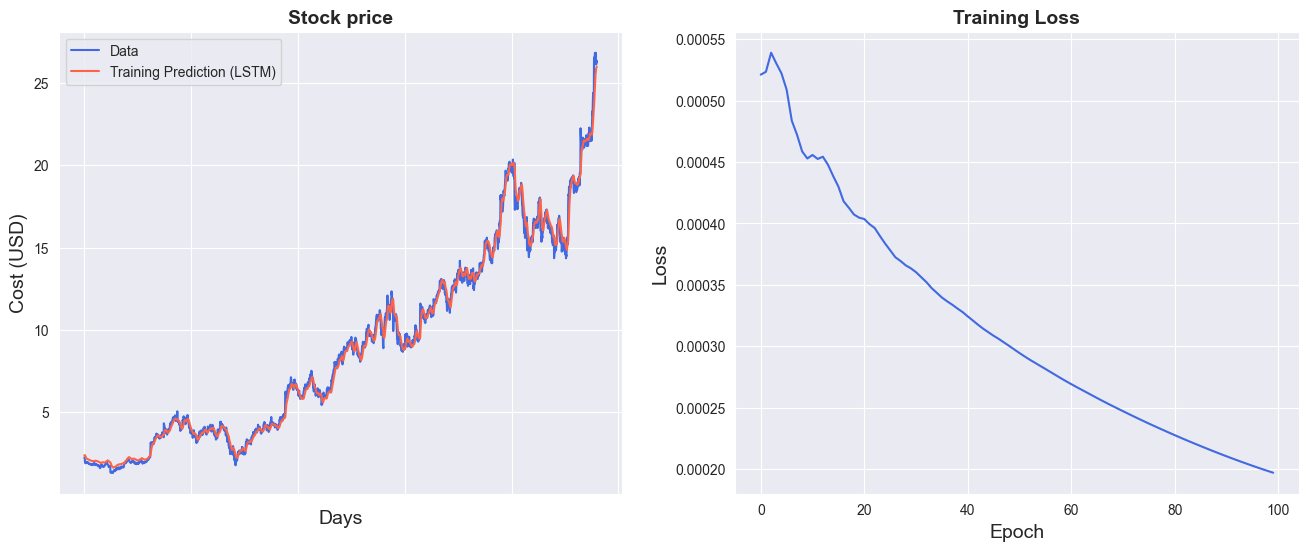

In [47]:
import seaborn as sns
sns.set_style("darkgrid")    

fig = plt.figure()
fig.subplots_adjust(hspace=0.2, wspace=0.2)

plt.subplot(1, 2, 1)
ax = sns.lineplot(x = original.index, y = original[0], label="Data", color='royalblue')
ax = sns.lineplot(x = predict.index, y = predict[0], label="Training Prediction (LSTM)", color='tomato')
ax.set_title('Stock price', size = 14, fontweight='bold')
ax.set_xlabel("Days", size = 14)
ax.set_ylabel("Cost (USD)", size = 14)
ax.set_xticklabels('', size=10)


plt.subplot(1, 2, 2)
ax = sns.lineplot(data=hist, color='royalblue')
ax.set_xlabel("Epoch", size = 14)
ax.set_ylabel("Loss", size = 14)
ax.set_title("Training Loss", size = 14, fontweight='bold')
fig.set_figheight(6)
fig.set_figwidth(16)

In [12]:
def run_epoch(model, criterion, loader, optimizer, is_train):
    if is_train:
        model.train()
    else:
        model.eval()
    
    epoch_loss = 0
    total_samples = 0

    for x, y in loader:
        if is_train:
            optimizer.zero_grad()
        
        x = x.to(device)
        y = y.to(device)
        
        batchsize = x.shape[0]
                            
        out = model(x)
        loss = criterion(out, y)

        if is_train:
            loss.backward()
            optimizer.step()

        epoch_loss += loss.item() * batchsize
        total_samples += batchsize
        #potential idea: only get validation loss every x epochs?
    
    return epoch_loss / total_samples


In [13]:
train_losses = np.zeros(epochs)
test_losses = np.zeros(epochs)

for epoch in tqdm(range(epochs)):
    train_loss = run_epoch(model, criterion, train_loader, optimizer, is_train=True)
    test_loss = run_epoch(model, criterion, test_loader, optimizer, is_train=False)
    train_losses[epoch] = train_loss
    test_losses[epoch] = test_loss

    if show_stats:
        tqdm.write(f"\rEpoch[{epoch+1}/{epochs}] | loss train: {train_loss}, test: {test_loss}", end="\r")


  0%|          | 0/100 [00:00<?, ?it/s]

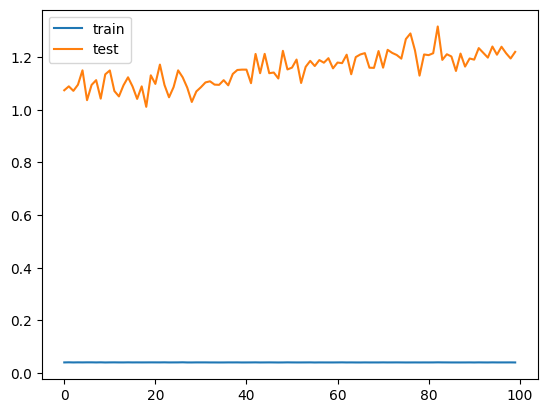

In [67]:
plt.plot(train_losses, label='train')

plt.plot(test_losses, label='test')

plt.legend()

plt.show()


In [68]:

model.eval()

predicted_train = np.array([])

for idx, (x, y) in enumerate(train_loader):
    x = x.to(device)
    out = model(x)
    out = out.cpu().detach().numpy()
    predicted_train = np.concatenate((predicted_train, out.squeeze(-1)))

In [69]:
dummy = np.zeros((predicted_train.shape[0], train_x.shape[1]))
dummy[:, 0] = predicted_train
dummy = scaler.inverse_transform(dummy)
predicted_train = dummy[:, 0]

NameError: name 'train_x' is not defined

In [17]:
to_plot_data_y_train_pred = np.zeros(len(data))

to_plot_data_y_train_pred[:split_index-block_size] = predicted_train

to_plot_data_y_train_pred = np.where(to_plot_data_y_train_pred == 0, None, to_plot_data_y_train_pred)


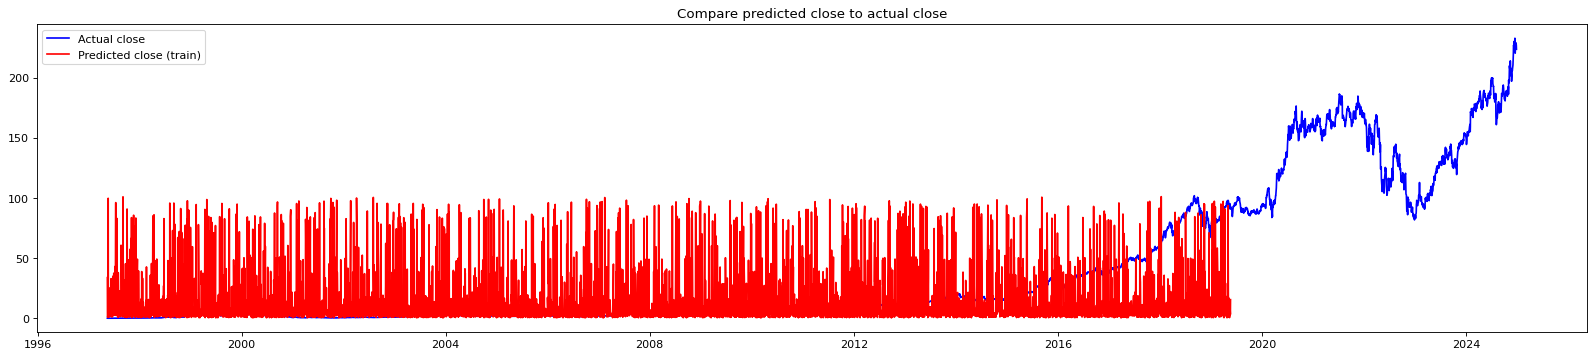

In [18]:

dates = data.index


fig = plt.figure(figsize=(25, 5), dpi=80)
fig.patch.set_facecolor((1.0, 1.0, 1.0))
plt.plot(dates, data["Close"], label="Actual close", color="blue")
plt.plot(dates, to_plot_data_y_train_pred, label="Predicted close (train)", color="red")
plt.title("Compare predicted close to actual close")
# plt.grid(b=None, which='major', axis='y', linestyle='--')
plt.legend()
plt.show()

In [19]:
predicted_train

array([33.82491096,  1.16298546,  1.94909275, ...,  9.59385139,
        3.22500841, 15.51753662])